# Single-crystal IR and Raman spectra of *Pnma* SnSe

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.offsetbox import AnchoredText

In [2]:
# Imports from the "core" Phonopy-Spectroscopy API.

from phonopy_spectroscopy.cli.utility.printing import (
    get_format_string, print_header, print_3x3_matrix
)

from phonopy_spectroscopy.instrument import (
    Geometry, Polarisation, SPPolarisation
)

from phonopy_spectroscopy.interfaces.phonopy_interface import (
    gamma_phonons_from_phono3py,
    eps_inf_and_born_from_born
)

from phonopy_spectroscopy.interfaces.vasp_interface import (
    structure_from_poscar, structure_to_poscar
)

from phonopy_spectroscopy.ir.calculation import InfraredCalculation
from phonopy_spectroscopy.raman.calculation import RamanCalculation

from phonopy_spectroscopy.raman.calculators import (
    FiniteDisplacementRamanTensorCalculator
)

from phonopy_spectroscopy.utility.io_helper import save_json, load_json

In [3]:
# Helper routines from the Phonopy-Spectroscopy CLI module.

from phonopy_spectroscopy.cli.io.raman import fd_read_dielectrics_vasp

from phonopy_spectroscopy.cli.io.peak_table import (
    infrared_dielectric_function_peak_table_to_txt,
    dielectric_function_to_txt,
    optical_spectrum_to_txt,
    raman_peak_table_to_txt,
    raman_spectrum_to_txt
)

from phonopy_spectroscopy.cli.utility.misc import get_crystal_rotation_matrix
from phonopy_spectroscopy.cli.plotting.style import set_plot_style

In [4]:
# Set default plot style (optional).

set_plot_style()

## Phonon calculation

In [5]:
# For this calculation we want to load the \eps_inf from a BORN file obtained
# using HSE06. To do this, we also need the crystal structure.

struct = structure_from_poscar(r"POSCAR.Opt")
eps_inf, _ = eps_inf_and_born_from_born(r"BORN.HSE06", struct)

ph_calc = gamma_phonons_from_phono3py(
    struct,
    r"mesh.yaml",
    lws_file=r"kappa-m323216-g0.hdf5",
    lws_t=300.0,
    irreps_file=r"irreps.yaml",
    born_file=r"BORN",
    eps_inf=eps_inf
)

## Dielectric properties

In [6]:
# Print dielectric constants \epsilon.

for label, eps in [
    (r"\eps_inf", ph_calc.epsilon_inf),
    (r"\eps_ionic", ph_calc.epsilon_ionic),
    (r"\eps_static", ph_calc.epsilon_static)
]:
    print(label)
    print("-" * len(label))

    print_3x3_matrix(eps)
    print("")

\eps_inf
--------
[   18.166    0.000    0.000  ]
[    0.000   21.277    0.000  ]
[    0.000    0.000   16.970  ]

\eps_ionic
----------
[   22.838   -0.000   -0.000  ]
[   -0.000   45.712   -0.000  ]
[   -0.000    0.000   28.832  ]

\eps_static
-----------
[   41.004   -0.000   -0.000  ]
[   -0.000   66.989   -0.000  ]
[   -0.000    0.000   45.802  ]



## Measurement geometry

In [7]:
# To model polarised IR and Raman measurements, we need to know how reorienting
# to align one of the major surfaces antiparallel to the incident light rotates
# the other axes.

fmt = get_format_string(struct.lattice_vectors)

print_header("Lattice vectors")

for l, v in zip("abc", struct.lattice_vectors):
    print("{0} =  [  {1}  {2}  {3}  ]".format(l, *[fmt.format(x) for x in v]))

print("")

# Backscattering measurement geometry for Raman - the "on axis" IR simulations
# also assume an incident direction along +z, the same rotations are valid for
# both simulations.

geom = Geometry("+z", "-z")

for hkl in (0, 0, 1), (1, 0, 0):
    print_header("{0}{1}{2} surface".format(*hkl))

    r = get_crystal_rotation_matrix(struct, hkl, geom)
    r_v_latt = r @ struct.lattice_vectors.T

    for l, v in zip("abc", r_v_latt):
        params = [l] + [fmt.format(x) for x in v]
        print("{0} -> [  {1}  {2}  {3}  ]".format(*params))

    print("")


Lattice vectors
---------------
a =  [    4.345    0.000    0.000  ]
b =  [    0.000    4.119    0.000  ]
c =  [    0.000    0.000   11.355  ]

001 surface
-----------
a -> [   -4.345    0.000    0.000  ]
b -> [    0.000    4.119    0.000  ]
c -> [   -0.000    0.000  -11.355  ]

100 surface
-----------
a -> [   -0.000    0.000  -11.355  ]
b -> [   -0.000   -4.119   -0.000  ]
c -> [   -4.345    0.000   -0.000  ]



# Infrared reflectivity and dielectric function

In [8]:
# Use ph_calc to create an InfraredCalculation object and serialise the
# calculation to JSON.

ir_calc = InfraredCalculation(ph_calc)

save_json(ir_calc.to_dict(), r"infrared_calculation.json")

In [9]:
# Uncomment to skip the previous steps and load the calculation from disk.

# ir_calc = InfraredCalculation.from_dict(
#     load_json(r"infrared_calculation.json")
# )

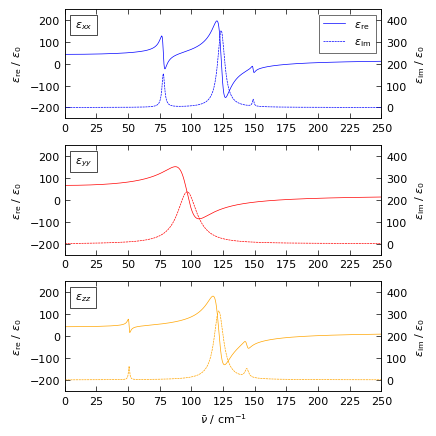

In [10]:
# Generate the "bulk" IR dielectric function. We explicitly disable
# non-analytical corrections (NAC) because these are specific to a given
# measurement geometry.

eps_ir = ir_calc.dielectric_function(
    nac=False, e_range=(0.0, 250.0), e_units="inv_cm"
)

# Plot the three diagonal components on separate subplots.

plt.figure(figsize=(11.2 / 2.54, 11.2 / 2.54))

sub_ax_re = [plt.subplot(3, 1, i + 1) for i in range(3)]
sub_ax_im = [ax.twinx() for ax in sub_ax_re]

plot_c = ["b", "r", "orange"]

for idx in range(3):
    sub_ax_re[idx].plot(
        eps_ir.energy,
        eps_ir.epsilon[:, idx, idx].real,
        label=r"$\varepsilon_\mathrm{re}$",
        color=plot_c[idx]
    )

    sub_ax_im[idx].plot(
        eps_ir.energy,
        eps_ir.epsilon[:, idx, idx].imag,
        label=r"$\varepsilon_\mathrm{im}$",
        color=plot_c[idx],
        dashes=(3.0, 1.0)
    )

x_ticks = np.linspace(0.0, 250.0, 11)
y_ticks = np.linspace(-200.0, 200.0, 5)

for ax in sub_ax_re:
    ax.set_xlim(0.0, 250.0)
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(-250.0, 250.0)
    ax.set_yticks(y_ticks)

y_ticks = np.linspace(0.0, 400.0, 5)

for ax in sub_ax_im:
    ax.set_ylim(-50.0, 450.0)
    ax.set_yticks(y_ticks)

sub_ax_re[-1].set_xlabel(eps_ir.energy_unit_plot_label)

for ax in sub_ax_re:
    ax.set_ylabel(r"$\varepsilon_\mathrm{re}$ / $\varepsilon_\mathrm{0}$")

for ax in sub_ax_im:
    ax.set_ylabel(r"$\varepsilon_\mathrm{im}$ / $\varepsilon_\mathrm{0}$")

h1, l1 = sub_ax_re[0].get_legend_handles_labels()
h2, l2 = sub_ax_im[0].get_legend_handles_labels()

sub_ax_re[0].legend(h1 + h2, l1 + l2, loc="upper right")

for idx, x in enumerate("xyz"):
    sub_ax_re[idx].add_artist(
        AnchoredText(rf"$\varepsilon_{{{x}{x}}}$", loc="upper left")
    )

plt.tight_layout()

plt.savefig(r"eps-ir-bulk.png")

In [11]:
# Display peak table.

# peak_table() returns the frequencies, oscillator strengths, linewidths and
# irreps as a Pandas DataFrame object.

df = eps_ir.peak_table()

# Drop columns for off-diagonal oscillator strengths.

df = df.drop(
    columns=[f"osc_str_{x}" for x in ("xy", "xz", "yx", "yz", "zx", "zy")]
)

print(df)

# Save the peak table and dielectric function to text files with units appended
# as headers.

infrared_dielectric_function_peak_table_to_txt(eps_ir, r"ir_peak_table.dat")
dielectric_function_to_txt(eps_ir, "eps-ir-bulk.dat")

       energy    osc_str_xx  osc_str_yy    osc_str_zz  linewidth irrep
0   50.729513  3.081488e-31    0.000000  1.532960e-02   0.595395   B3u
1   77.773272  1.266687e-01    0.000000  0.000000e+00   1.294690   B1u
2   96.634298  0.000000e+00    1.763229  0.000000e+00   9.302881   B2u
3  121.581333  0.000000e+00    0.000000  1.443323e+00   4.561965   B3u
4  123.495181  1.218175e+00    0.000000  6.039716e-31   3.398612   B1u
5  143.700417  0.000000e+00    0.000000  7.948408e-02   1.708572   B3u
6  148.739604  2.924148e-02    0.000000  0.000000e+00   0.755257   B1u


/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/optics/spectrum.py:113: RuntimeWarning: divide by zero encountered in log10
  abs = -1.0 * np.log10(self._trans)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/optics/optical_eigenmodes.py:609: RuntimeWarning: divide by zero encountered in log10
  abs_int = -1.0 * np.log10(self._trans_int)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/optics/spectrum.py:113: RuntimeWarning: divide by zero encountered in log10
  abs = -1.0 * np.log10(self._trans)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/optics/optical_eigenmodes.py:609: RuntimeWarning: divide by zero encountered in log10
  abs_int = -1.0 * np.log10(self._trans_int)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/optics/spectrum.py:113: RuntimeWarning: divide by zero encountered in log10
  abs = -1.0 * np.log10(self._trans)
/Use

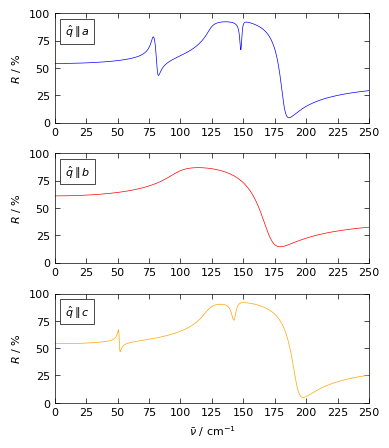

In [12]:
# Simulate the IR reflectivity spectra for different surfaces and incident
# polarisations.

# Define measurement geometries.

params = [
    ((0, 0, 1), "-x"),  # e_i || a
    ((0, 0, 1), "+y"),  # e_i || b
    ((1, 0, 0), "-x")   # e_i || c
]

spectra = []

for hkl, i_pol_dir in params:
    # The IR routines use the conventional s/p polarisation specification. In
    # this example it is more convenient to specify them in Cartesian
    # coordinates and convert to the s/p basis using the incident and normal
    # directions (both +z for on-axis measurements).
    
    i_pol = SPPolarisation.from_direction(i_pol_dir, q="+z", n="+z")
    
    sp = ir_calc.incoherent_single_crystal_on_axis_spectrum(
        hkl, i_pol=i_pol, e_range=(0.0, 250.0), e_units="inv_cm"
    )

    spectra.append(sp)

# Save spectra. This also includes transmission, absorption and "total"
# reflectivity for the default sample thickness of 1 mm - 1 mm is far too thick
# for SnSe, and for a transmission spectrum setting t=1e-3 (1 um) when
# generating the spectra will give more reasonable results for these properties.

for sp, ax in zip(spectra, "abc"):
    optical_spectrum_to_txt(sp, rf"ir-reflectivity-{ax}.dat")

# Plot the three reflectivity spectra.

plt.figure(figsize=(10.0 / 2.54, 11.5 / 2.54))

sub_ax = [plt.subplot(3, 1, i + 1) for i in range(3)]

plot_c = ["b", "r", "orange"]

for idx, sp in enumerate(spectra):
    sub_ax[idx].plot(
        sp.energy,
        100.0 * sp.single_reflectivity,
        color=plot_c[idx]
    )

x_ticks = np.linspace(0.0, 250.0, 11)

for ax in sub_ax:
    ax.set_xlim(0.0, 250.0)
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(0.0, 100.0)

sub_ax[-1].set_xlabel(spectra[0].energy_unit_plot_label)

for ax in sub_ax:
    ax.set_ylabel("$R$ / %")

for idx, dirn in enumerate("abc"):
    sub_ax[idx].add_artist(
        AnchoredText(rf"$\hat{{q}} \parallel {{{dirn}}}$", loc="upper left")
    )

plt.tight_layout()

plt.savefig(r"ir-reflectivity.png")

## Raman spectra

In [13]:
# Set up a finite-displacement Raman calculation. The default two-point central
# difference scheme and selection of Raman-active bands excluding any acoustic
# modes are usually sufficient, but the step size is system dependent.

fd_calc = FiniteDisplacementRamanTensorCalculator(ph_calc, step_size=1.0e-1)

# Check maximum Cartesian displacements along each Raman-active mode. We ideally
# want the displacements to be on the order of 1.0e-2, as we would typically use
# for a finite-displacement phonon calculation.

max_disps = fd_calc.get_maximum_displacements()

print_header("Displacements")

for idx, disps in zip(fd_calc.band_indices, max_disps):
    print("Mode {0: >2}: {1:.2e}, {2:.2e}".format(idx + 1, *disps))

# fd_calc can be serialised to JSON and reloaded from disk.

# save_json(fd_calc.to_dict(), r"raman_calculator.json")

# fd_calc = FiniteDisplacementRamanTensorCalculator.from_dict(
#     load_json(r"raman_calculator.json")
# )

Displacements
-------------
Mode  4: 4.02e-03, 4.02e-03
Mode  5: 3.58e-03, 3.58e-03
Mode  8: 4.14e-03, 4.14e-03
Mode  9: 4.09e-03, 4.09e-03
Mode 10: 3.64e-03, 3.64e-03
Mode 11: 3.67e-03, 3.67e-03
Mode 14: 4.39e-03, 4.39e-03
Mode 18: 4.55e-03, 4.55e-03
Mode 19: 5.08e-03, 5.08e-03
Mode 21: 5.02e-03, 5.02e-03
Mode 23: 4.69e-03, 4.69e-03
Mode 24: 4.50e-03, 4.50e-03


In [14]:
# Generate and save displaced structures as POSCAR files.

structs = fd_calc.get_displaced_structures()

for n, m in np.ndindex(*structs.shape):
    band_idx = fd_calc.band_indices[n]
    
    structure_to_poscar(
        structs[n, m], f"POSCAR-{band_idx + 1:0>4}-{m + 1:0>2}"
    )

In [15]:
# Read dielectric function calculations and use the calculator to generate a
# RamanTensors object.

file_list = []

for n, m in np.ndindex(fd_calc.num_bands, fd_calc.num_steps):
    band_idx = fd_calc.band_indices[n]
    file_list.append(rf"raman_ref/vasprun-{band_idx + 1:0>4}-{m + 1:0>2}.xml")

epss = fd_read_dielectrics_vasp(file_list, fd_calc.num_bands, fd_calc.num_steps)

# Finally, use the RamanTensors object to initialise a RamanCalculation, which
# can also be serialised to JSON. Note that RamanTensors objects store the
# phonon calculation used to generate them.

r_t = fd_calc.get_raman_tensors(epss)

raman_calc = RamanCalculation(r_t)

save_json(raman_calc.to_dict(), r"raman_calculation.json")

In [16]:
# Uncomment to skip the previous steps and load the calculation from disk.

# raman_calc = RamanCalculation.from_dict(load_json(r"raman_calculation.json"))

In [17]:
# Simulate Raman spectra for different surfaces and incident polarisations.

# Measurement geometries.

geom = Geometry.conventional_backscattering()

params = [
    ((0, 0, 1), "-y", "-y"),
    ((0, 0, 1), "-x", "-x"),
    ((0, 0, 1), "-x", "-y"),
    ((1, 0, 0), "-y", "-x"),
    ((0, 1, 0), "-x", "-y")
]

spectra = []

for hkl, i_pol_dir, s_pol_dir in params:
    # In Raman calculations, the polarisations are conventionally defined in
    # Cartesian coordinates.
    
    i_pol = Polarisation.from_direction(i_pol_dir)
    s_pol = Polarisation.from_direction(s_pol_dir)
    
    sp = raman_calc.single_crystal(
        hkl,
        geom,
        i_pol=i_pol,
        s_pol=s_pol,
        w=647.1,
        sp_range=(0.0, 250.0),
        sp_units="inv_cm"
    )

    spectra.append(sp)

In [18]:
# Display peak tables and save peak tables/spectra.

pol_ax = ["c(bb)-c", "c(aa)-c", "c(ab)c", "a(bc)-a", "b(ac)-b"]

for pol_ax, sp in zip(pol_ax, spectra):
    df = sp.peak_table()
    
    print_header(f"Geometry: {pol_ax}", newline=True)
    
    print(df)
    print("\n")

    raman_peak_table_to_txt(sp, rf"raman-peak_table-{pol_ax}.dat")
    raman_spectrum_to_txt(sp, rf"raman-spectrum-{pol_ax}.dat")

Geometry: c(bb)-c
-----------------

    raman_shift    intensity  cross_section  linewidth irrep
0     34.660106   104.195270   2.915021e-10   1.132265    Ag
1     37.137008     0.000074   1.802515e-16   0.505659   B3g
2     54.450248     0.000000   0.000000e+00   0.779571   B1g
3     65.194678     0.000000   0.000000e+00   1.218019   B2g
4     67.978593   536.050220   4.172857e-10   1.522865    Ag
5     68.797175     0.000000   0.000000e+00   0.698091   B2g
6    111.993827     0.000089   2.798041e-17   5.993592   B3g
7    131.443077  7512.439544   1.769884e-09   4.517833    Ag
8    137.001678     0.000008   1.811488e-18   1.659045   B1g
9    146.712182     0.000022   4.285434e-18   1.823863   B2g
10   153.584622  4562.509397   8.205174e-10   1.367663    Ag
11   180.734799     0.000000   0.000000e+00   8.421539   B2g


Geometry: c(aa)-c
-----------------

    raman_shift     intensity  cross_section  linewidth irrep
0     34.660106  1.539363e+02   4.306603e-10   1.132265    Ag
1     3

/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/raman/spectrum.py:204: RuntimeWarning: divide by zero encountered in divide
  ((1.0e12 * (f_i - s)) ** 4) / (1.0e12 * np.abs(s))
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/distributions.py:257: RuntimeWarning: divide by zero encountered in divide
  n = 1.0 / (np.exp(e / (BOLTZMANN_CONSTANT_EV * t)) - 1.0)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/raman/spectrum.py:204: RuntimeWarning: divide by zero encountered in divide
  ((1.0e12 * (f_i - s)) ** 4) / (1.0e12 * np.abs(s))
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/distributions.py:257: RuntimeWarning: divide by zero encountered in divide
  n = 1.0 / (np.exp(e / (BOLTZMANN_CONSTANT_EV * t)) - 1.0)
/Users/user/Desktop/Repositories/Phonopy-Spectroscopy/lib/phonopy_spectroscopy/raman/spectrum.py:204: RuntimeWarning: divide by zero encountered in divide
 

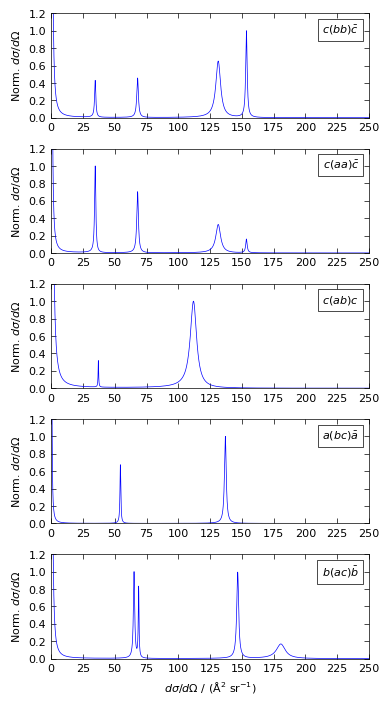

In [19]:
# Plot the five Raman spectra.

plt.figure(figsize=(10.0 / 2.54, 18.0 / 2.54))

sub_ax = [plt.subplot(5, 1, i + 1) for i in range(5)]

for idx, sp in enumerate(spectra):
    # The simulated spectra show the Rayleigh line, i.e. \sigma -> \inf as
    # \omega -> 0. If we want to normalise, we need to take the maximum starting
    # at a sensible frequency.
    
    mask = sp.raman_shift > 5.0
    
    sub_ax[idx].plot(
        sp.raman_shift,
        sp.cross_section / sp.cross_section[mask].max(),
        color="b"
    )

x_ticks = np.linspace(0.0, 250.0, 11)
y_ticks = np.linspace(0.0, 1.2, 7)

for ax in sub_ax:
    ax.set_xlim(0.0, 250.0)
    ax.set_xticks(x_ticks)
    
    ax.set_ylim(0.0, 1.2)
    ax.set_yticks(y_ticks)

sub_ax[-1].set_xlabel(spectra[0].cross_section_unit_plot_label)

for ax in sub_ax:
    ax.set_ylabel(r"Norm. $d \sigma / d \Omega$")

labels = [
    r"$c(bb)\bar{c}$",
    r"$c(aa)\bar{c}$",
    r"$c(ab)c$",
    r"$a(bc)\bar{a}$",
    r"$b(ac)\bar{b}$"
]

for idx, l in enumerate(labels):
    sub_ax[idx].add_artist(AnchoredText(l, loc="upper right"))

plt.tight_layout()

plt.savefig(r"raman-spectra.png")